In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt


%matplotlib inline

In [2]:
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
) # Validation

In [3]:
train = pd.read_csv("train.csv")
econ = pd.read_csv("economic_indicators.csv")

In [4]:
train.columns = train.columns.str.lower().str.replace(" ", "_", regex=False)
econ.columns = econ.columns.str.lower().str.replace(" ", "_", regex=False)


# Columns to exclude from model features
exclude_cols = ['id', 'target']

# Identifiers that should not automatically be treated as continuous numbers
id_cols = ['customer_id', 'country_id', 'tbl_loan_id', 'lender_id']

# Dates
date_cols = ['disbursement_date', 'due_date']
# Convert dates
for col in date_cols:
    train[col] = pd.to_datetime(train[col], errors='coerce')

for category in ["country_id", "loan_type", "new_versus_repeat"]:
    train[category] = train[category].str.lower().str.replace(" ", "_")

for cat in ["country", "indicator"]:
    econ[cat] = econ[cat].str.lower().str.replace(" ", "_")

# date-based features
train['loan_year'] = train["disbursement_date"].dt.year
train['loan_month'] = train["disbursement_date"].dt.month

# financial features
train["interest_amount"] = train.total_amount_to_repay - train.total_amount
train["repayment_ratio"] = train.total_amount_to_repay / train.total_amount


# Handling Outliers: use np.log1p()
train["duration_log"] = np.log1p(train["duration"])
train["total_amount_log"] = np.log1p(train['total_amount'])


In [5]:
# Prepare econ for merging
# Identify year columns
year_cols = [col for col in econ.columns if col.startswith('yr')]

# Convert wide to long format
econ_long = econ.melt(
    id_vars=['country', 'indicator'],
    value_vars=year_cols,
    var_name='year',
    value_name='economic_value'
)

# Extract numeric year
econ_long['year'] = econ_long['year'].str.replace('yr', '').astype(int)

# Pivot economic indicators into columns
econ_wide = econ_long.pivot_table(
    index=['country', 'year'],
    columns='indicator',
    values='economic_value',
    aggfunc='first'
).reset_index()

# Remove the columns index name
econ_wide.columns.name = None
# econ_wide[econ_wide.country == "kenya"]

In [6]:
train.rename(columns={'country_id': 'country'}, inplace=True)

# Merge economic indicators using country and year
combined = train.merge(
    econ_wide,
    left_on=['country', 'loan_year'],
    right_on=['country', 'year'],
    how='left',
    validate='many_to_one'
)

# Remove the redundant year column
combined.drop(columns=['year'], inplace=True)
# combined.head()

In [7]:

# Define categorical and numerical columns
# Categorical features
categorical_cols = [
    'country',
    'loan_type',
    'new_versus_repeat',
]
# Add lender_id only if you want to test its predictive value
# categorical_cols.append('lender_id')
categorical_cols = [
    col for col in categorical_cols
    if col in combined.columns
]
# Exclude target and identifier columns from numerical features
exclude_cols = [
    'target',
    'id',
    'customer_id',
    'tbl_loan_id',
    'lender_id',
    'duration',# use the log variant
    'total_amount', # use the log variant
    'average_precipitation_in_depth_(mm_per_year)', # produce NaN and have a low correlation to target
    'fossil_fuel_energy_consumption_(%_of_total)', # produce NaN and have a low correlation to target
]


numerical_cols = [
    col for col in combined.select_dtypes(include='number').columns
    if col not in exclude_cols
]
print("Categorical features:", categorical_cols)
print("Numerical features:", numerical_cols)


Categorical features: ['country', 'loan_type', 'new_versus_repeat']
Numerical features: ['total_amount_to_repay', 'amount_funded_by_lender', 'lender_portion_funded', 'lender_portion_to_be_repaid', 'loan_year', 'loan_month', 'interest_amount', 'repayment_ratio', 'duration_log', 'total_amount_log', 'deposit_interest_rate_(%)', 'inflation,_consumer_prices_(annual_%)', 'interest_rate_spread_(lending_rate_minus_deposit_rate,_%)', 'lending_interest_rate_(%)', 'official_exchange_rate_(lcu_per_us$,_period_average)', 'real_interest_rate_(%)', 'unemployment_rate']


In [8]:
from sklearn.metrics import mutual_info_score

def mutual_info_target_score(series):
    return mutual_info_score(series, train.target)

mi = train[categorical_cols].apply(mutual_info_target_score)
mi.sort_values(ascending=False)
print(f"mutual info score:\n {mi}\n")

ans = {}
for column in numerical_cols:
    corr = combined[column].corr(combined['target'])
    key = f"{column}"
    ans[key] = corr
print(f"numerical_columns correlation to target:\n {ans}\n")

mutual info score:
 country              0.000000
loan_type            0.015103
new_versus_repeat    0.002525
dtype: float64

numerical_columns correlation to target:
 {'total_amount_to_repay': np.float64(0.07385302532419592), 'amount_funded_by_lender': np.float64(0.10377741175311125), 'lender_portion_funded': np.float64(0.04579732878048301), 'lender_portion_to_be_repaid': np.float64(0.11072786410708564), 'loan_year': np.float64(0.1254021678337026), 'loan_month': np.float64(-0.06880578596760357), 'interest_amount': np.float64(0.06295584305396335), 'repayment_ratio': np.float64(0.6501951337514946), 'duration_log': np.float64(0.21559463450276128), 'total_amount_log': np.float64(0.06842251219484996), 'deposit_interest_rate_(%)': np.float64(0.1051029177551162), 'inflation,_consumer_prices_(annual_%)': np.float64(-0.08629764814697098), 'interest_rate_spread_(lending_rate_minus_deposit_rate,_%)': np.float64(-0.1044864769123655), 'lending_interest_rate_(%)': np.float64(0.10547978790387627), '

In [9]:
from sklearn.model_selection import train_test_split

# Split off the test set (20%)
df_full_train, df_test = train_test_split(
    combined,
    test_size=0.2,
    random_state=1,
    stratify=combined['target']
)

# Split remaining 80% into 60% train and 20% validation
df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1,
    stratify=df_full_train['target']
)

# Reset indices
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)


y_full_train = df_full_train['target'].values
y_train = df_train['target'].values
y_val = df_val['target'].values
y_test = df_test['target'].values

del df_full_train['target']
del df_train['target']
del df_val['target']
del df_test['target']



X_full_train = df_full_train[numerical_cols + categorical_cols]
X_train = df_train[numerical_cols + categorical_cols]
X_val = df_val[numerical_cols + categorical_cols]
X_test = df_test[numerical_cols + categorical_cols]

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer


# Create preprocessing pipelines
# Numerical preprocessing
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
# Categorical preprocessing
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])
# Combine the pipelines
preprocessor = ColumnTransformer([
    ('numerical', numerical_pipeline, numerical_cols),
    ('categorical', categorical_pipeline, categorical_cols),
])


In [11]:
# logistic_regression
logistic_regression_score = {}

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000)),
])
model.fit(X_train, y_train)

feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()
# print(feature_names)

In [13]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

import time

start_time = time.perf_counter()


pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=3000))
])
param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': [None, 'balanced']
}
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    # scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    refit=True
)
grid_search.fit(X_train, y_train)

end_time = time.perf_counter()
execution_time = end_time - start_time
print(f"Function took {execution_time:.6f} seconds to execute.")

best_model = grid_search.best_estimator_
logistic_regression_score["cross_validation"] = grid_search.best_params_

print("Hyper_parameter tuning for logistic regression")
print("Best parameters:", grid_search.best_params_)
print("Best score:", round(grid_search.best_score_, 4))

Function took 45.511344 seconds to execute.
Hyper_parameter tuning for logistic regression
Best parameters: {'classifier__C': 100, 'classifier__class_weight': None}
Best score: 0.9896


In [14]:
# Training final logistic regression model with hyperparametrized values
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_reg_C = 0.1
logistic_reg_class_weight = "balanced"


logistic = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, C=logistic_reg_C, class_weight=logistic_reg_class_weight)),
])
logistic.fit(X_full_train, y_full_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['total_amount_to_repay','amount_funded_by_lender','lender_portion_funded', ...,'country','loan_type','new_versus_repeat']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (

In [15]:
y_full_pred = logistic.predict_proba(X_test)[:, 1]
y_pred = model.predict_proba(X_test)[:, 1]

auc_after_tuning = roc_auc_score(y_test, y_full_pred)
auc_before_tuning = roc_auc_score(y_test, y_pred)

print(f"auc before hyperparameter tuning: {round(auc_before_tuning, 4)}, auc after hyperparameter tuning: {round(auc_after_tuning, 4)}")

auc before hyperparameter tuning: 0.9867, auc after hyperparameter tuning: 0.9845


In [16]:
# decision tree
decision_tree_score = {}

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42)),
])

model.fit(X_train, y_train)

feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()

In [18]:
from sklearn.metrics import roc_auc_score

y_train_proba = model.predict_proba(X_train)[:, 1]
y_val_proba = model.predict_proba(X_val)[:, 1]

print("Training ROC-AUC:", roc_auc_score(y_train, y_train_proba))
print("Validation ROC-AUC:", roc_auc_score(y_val, y_val_proba))

y_test_proba = model.predict_proba(X_test)[:, 1]

print("Test ROC-AUC:", roc_auc_score(y_test, y_test_proba))

Training ROC-AUC: 1.0
Validation ROC-AUC: 0.8972515447309573
Test ROC-AUC: 0.9194107942160469


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

import time

start_time = time.perf_counter()

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42)),
])
param_grid = {
    'classifier__max_depth': [3, 5, 10, 15, 20, None],
    'classifier__min_samples_split': [2, 10, 20, 50],
    'classifier__min_samples_leaf': [1, 5, 10, 20],
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__class_weight': [None, 'balanced'],
}
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    # scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)

end_time = time.perf_counter()
execution_time = end_time - start_time
print(f"Function took {execution_time:.6f} seconds to execute.")

best_model = grid_search.best_estimator_
decision_tree_score["cross_validation"] = grid_search.best_params_

# Hyper_parameter tuning for Decision Tree
print("Best parameters:", grid_search.best_params_)
print("Best score:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 384 candidates, totalling 1920 fits
Function took 293.417580 seconds to execute.
Best parameters: {'classifier__class_weight': None, 'classifier__criterion': 'entropy', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}
Best score: 0.9943


In [20]:
# Training final model with parameters
class_weight = None
criterion = 'entropy'
max_depth = 5
min_samples_leaf = 20
min_samples_split = 2

decision_tree = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42,
                                          class_weight=class_weight,
                                          criterion=criterion,
                                          max_depth=max_depth,
                                          min_samples_leaf=min_samples_leaf,
                                          min_samples_split=min_samples_split)),
])

decision_tree.fit(X_full_train, y_full_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['total_amount_to_repay','amount_funded_by_lender','lender_portion_funded', ...,'country','loan_type','new_versus_repeat']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (

In [21]:
y_full_pred = decision_tree.predict_proba(X_test)[:, 1]
y_pred = model.predict_proba(X_test)[:, 1]

auc_after_tuning = roc_auc_score(y_test, y_full_pred)
auc_before_tuning = roc_auc_score(y_test, y_pred)

print(f"auc before hyperparameter tuning: {round(auc_before_tuning, 4)}, auc after hyperparameter tuning: {round(auc_after_tuning, 4)}")

auc before hyperparameter tuning: 0.9072, auc after hyperparameter tuning: 0.9905


In [22]:
# random forrest
random_forest_score = {}

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1)),
])

model.fit(X_train, y_train)

feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()

In [24]:
for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test),
]:
    y_proba = model.predict_proba(X)[:, 1]
    print(f"{name} ROC-AUC: {roc_auc_score(y, y_proba):.4f}")

Train ROC-AUC: 1.0000
Validation ROC-AUC: 0.9863
Test ROC-AUC: 0.9844


In [25]:
# rf = model.named_steps['classifier']

# print("Number of trees:", rf.n_estimators)
# print("Maximum tree depth:", max(
#     tree.get_depth() for tree in rf.estimators_
# ))

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

import time

start_time = time.perf_counter()


pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        random_state=42,
        n_jobs=1,
        # n_jobs=-1
    )),
])
param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [None, 10, 20, 30],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 5],
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__class_weight': [None, 'balanced'],
}
cv = StratifiedKFold(
    # n_splits=5,
    n_splits=2,
    shuffle=True,
    random_state=42
)
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    # scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)

end_time = time.perf_counter()
execution_time = end_time - start_time
print(f"Function took {execution_time:.6f} seconds to execute.") # Function took 2023.869116 seconds to execute.~30 minutes

best_model = grid_search.best_estimator_
random_forest_score["cross_validation"] = grid_search.best_score_

print("Best parameters:", grid_search.best_params_)
print("Best score:", round(grid_search.best_score_, 4))

Fitting 2 folds for each of 432 candidates, totalling 864 fits
Function took 1001.538236 seconds to execute.
Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Best score: 0.9945


In [27]:
# Training final model: Random Forest
class_weight = 'balanced'
max_depth = 20
max_features = 'sqrt'
min_samples_leaf = 2
min_samples_split = 2
n_estimators = 300

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42,
                                          class_weight=class_weight,
                                          max_depth=max_depth,
                                          max_features=max_features,
                                          min_samples_leaf=min_samples_leaf,
                                          min_samples_split=min_samples_split,
                                          n_estimators=n_estimators,
                                          n_jobs=-1)),
])

random_forest.fit(X_full_train, y_full_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['total_amount_to_repay','amount_funded_by_lender','lender_portion_funded', ...,'country','loan_type','new_versus_repeat']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (

In [28]:
y_full_pred = random_forest.predict_proba(X_test)[:, 1]
y_pred = model.predict_proba(X_test)[:, 1]

auc_after_tuning = roc_auc_score(y_test, y_full_pred)
auc_before_tuning = roc_auc_score(y_test, y_pred)

print(f"auc before hyperparameter tuning: {round(auc_before_tuning, 4)}, auc after hyperparameter tuning: {round(auc_after_tuning, 4)}")

auc before hyperparameter tuning: 0.9825, auc after hyperparameter tuning: 0.9922


In [29]:
# XGBoost
xgboost_score = {}

In [30]:
import xgboost as xgb
from sklearn.pipeline import Pipeline

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb.XGBClassifier(
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss'
    )),
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['total_amount_to_repay','amount_funded_by_lender','lender_portion_funded', ...,'country','loan_type','new_versus_repeat']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (

In [31]:
for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test),
]:
    y_proba = model.predict_proba(X)[:, 1]
    print(f"{name} ROC-AUC: {roc_auc_score(y, y_proba):.4f}")

Train ROC-AUC: 1.0000
Validation ROC-AUC: 0.9968
Test ROC-AUC: 0.9941


In [32]:
import xgboost as xgb
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

import time
start_time = time.perf_counter()


# Calculate class imbalance ratio
y_array = np.asarray(y_train)
n_negative = np.sum(y_array == 0)
n_positive = np.sum(y_array == 1)

if n_positive == 0 or n_negative == 0:
    raise ValueError("y_train must contain both classes, encoded as 0 and 1.")

imbalance_ratio = n_negative / n_positive

# Build pipeline
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb.XGBClassifier(
        objective='binary:logistic',
        random_state=42,
        eval_metric='aucpr',
        tree_method='hist',
        n_jobs=1
    )),
])
# Define parameter grid
param_grid = {
    'classifier__n_estimators': [200, 400],
    'classifier__max_depth': [3, 5, 7],
    'classifier__learning_rate': [0.01, 0.05, 0.1],
    'classifier__min_child_weight': [1, 5],
    'classifier__subsample': [0.8, 1.0],
    'classifier__colsample_bytree': [0.8, 1.0],
    'classifier__scale_pos_weight': [
        1,
        max(1, imbalance_ratio * 0.5),
        imbalance_ratio
    ]
}
# Stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
# Grid search
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    # scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)
# Fit the search
grid_search.fit(X_train, y_train)

end_time = time.perf_counter()
execution_time = end_time - start_time
print(f"Function took {execution_time:.6f} seconds to execute.") # Function took 2023.869116 seconds to execute.~30 minutes

# Best model
best_model = grid_search.best_estimator_

xgboost_score["cross_validation"] = grid_search.best_score_


print("Best score:", grid_search.best_score_)
print("\nBest Parameters:")
print(grid_search.best_params_)

Fitting 5 folds for each of 432 candidates, totalling 2160 fits
Function took 1283.525397 seconds to execute.
Best score: 0.9949747382172456

Best Parameters:
{'classifier__colsample_bytree': 1.0, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 7, 'classifier__min_child_weight': 1, 'classifier__n_estimators': 400, 'classifier__scale_pos_weight': 1, 'classifier__subsample': 1.0}


In [33]:
# Training final model: XGBoost
import xgboost as xgb
from sklearn.pipeline import Pipeline

colsample_bytree = 1.0
learning_rate = 0.05
max_depth = 7
min_child_weight = 1
n_estimators = 200
scale_pos_weight = 1
subsample = 0.8


xgboost = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb.XGBClassifier(
        random_state=42,
        n_jobs=-1,
        
        colsample_bytree = colsample_bytree,
        learning_rate=learning_rate,
        max_depth=max_depth,
        min_child_weight=min_child_weight,
        n_estimators=n_estimators,
        scale_pos_weight=scale_pos_weight,
        subsample=subsample,
        
        eval_metric='logloss'
    )),
])

xgboost.fit(X_full_train, y_full_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['total_amount_to_repay','amount_funded_by_lender','lender_portion_funded', ...,'country','loan_type','new_versus_repeat']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (

In [34]:
for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test),
]:
    y_proba = xgboost.predict_proba(X)[:, 1]
    print(f"{name} ROC-AUC: {roc_auc_score(y, y_proba):.4f}")

Train ROC-AUC: 0.9997
Validation ROC-AUC: 0.9996
Test ROC-AUC: 0.9941


In [35]:
print(f"logistic_regression_score: \n{logistic_regression_score}\n")
print(f"decision_tree_score: \n{decision_tree_score}\n")
print(f"random_forest_score: \n{random_forest_score}\n")
print(f"xgboost_score: \n{xgboost_score}\n")

logistic_regression_score: 
{'cross_validation': {'classifier__C': 100, 'classifier__class_weight': None}}

decision_tree_score: 
{'cross_validation': {'classifier__class_weight': None, 'classifier__criterion': 'entropy', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}}

random_forest_score: 
{'cross_validation': np.float64(0.9944892212080017)}

xgboost_score: 
{'cross_validation': np.float64(0.9949747382172456)}



In [36]:
# Evaluate and save the best model
# Compare models on the held-out set with accuracy, precision, recall, F1 and ROC-AUC, plot confusion matrices and ROC curves,/
# choose the final model with a justification, and save both the model and the preprocessing pipeline with joblib.

# Which model did you choose, and why is it better for the lender than the one with the highest accuracy?
# What are its recall and precision on the default class, and what does each error cost the business?


In [39]:
# Evaluation metrics

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
)

# Generate predictions
y_pred = xgboost.predict(X_test)

# Probabilities for the positive class (target = 1)
y_prob = xgboost.predict_proba(X_test)[:, 1]

# Calculate metrics
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(
        y_test, y_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
}

metrics_df = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Score"],
)

print(metrics_df.to_string(index=False, formatters={
    "Score": "{:.4f}".format
}))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0,
))

   Metric  Score
 Accuracy 0.9959
Precision 0.9016
   Recall 0.8730
 F1-Score 0.8871
  ROC-AUC 0.9941

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     13479
           1       0.90      0.87      0.89       252

    accuracy                           1.00     13731
   macro avg       0.95      0.94      0.94     13731
weighted avg       1.00      1.00      1.00     13731



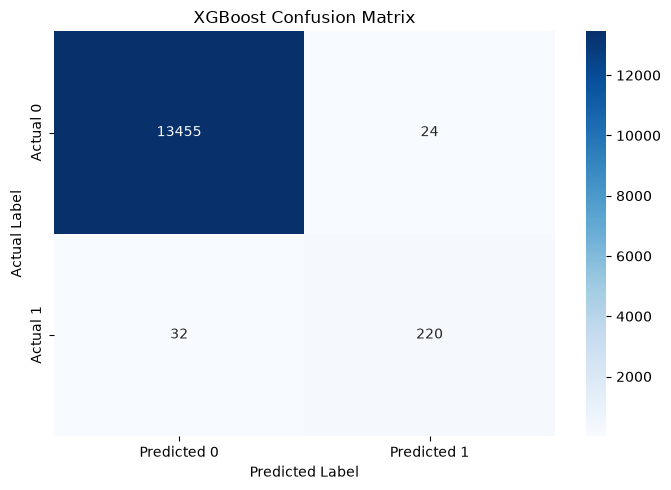

In [40]:
# Confusion matrix

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1],
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"],
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

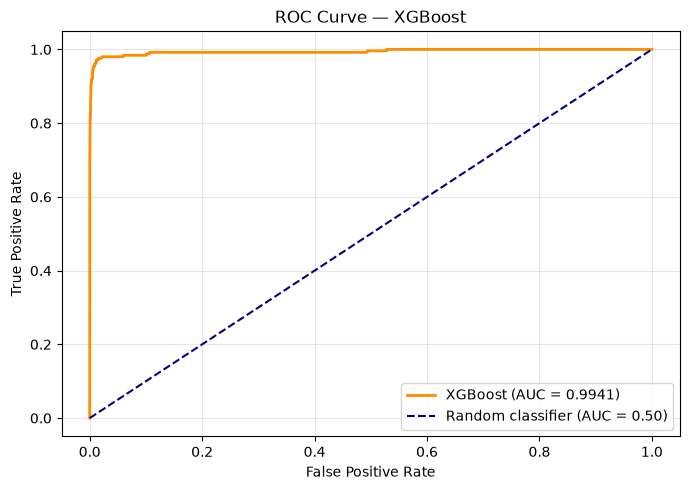

In [41]:
# Plot ROC curve

from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob,
)

auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    color="darkorange",
    linewidth=2,
    label=f"XGBoost (AUC = {auc_score:.4f})",
)

plt.plot(
    [0, 1],
    [0, 1],
    color="navy",
    linestyle="--",
    label="Random classifier (AUC = 0.50)",
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — XGBoost")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
# save the model

import joblib

joblib.dump(
    {
        "model": xgboost,
        "numerical_cols": numerical_cols,
        "categorical_cols": categorical_cols,
    },
    "xgboost_pipeline.joblib",
)

print("Saved xgboost_pipeline.joblib")

Saved xgboost_pipeline.joblib


In [ ]:
# uvicorn app:app --reload
loan_request = {
  "ID": "ID_257244237466267278",
  "customer_id": 257244,
  "country_id": "Kenya",
  "tbl_loan_id": 237466,
  "lender_id": 267278,
  "loan_type": "Type_1",
  "Total_Amount": 16477.0,
  "Total_Amount_to_Repay": 16642.0,
  "disbursement_date": "2022-08-15",
  "due_date": "2022-08-22",
  "duration": 7,
  "New_versus_Repeat": "Repeat Loan",
  "Amount_Funded_By_Lender": 2436.0,
  "Lender_portion_Funded": 0.147842447047399,
  "Lender_portion_to_be_repaid": 2460.0
}